# 01 · Model settings: where they come from and how much they matter

Build step 7. The expectation model's settings live in `config/config.yaml`. Some were fixed by the pre-registration, the LightGBM ones were chosen once and never documented. This notebook records the origin of each, confirms that the published model is reproduced exactly from the data on disk, and measures how coverage, fit and the flagged tracts change when each setting is varied on its own (buildings, the primary layer). It is a post-hoc sensitivity analysis: the primary specification is not changed by it, and no audit variable is used. The refits are done by `modelling/build/run_settings_grid.py` (about 30 minutes); this notebook only reads its results.

In [1]:
import warnings, os, json
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name in ("modelling", "notebooks", "eda") else Path.cwd()
os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 3)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
TAB, FIG = Path("modelling/tables"), Path("modelling/figures"); FIG.mkdir(parents=True, exist_ok=True)
def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight"); plt.show()
cfg = yaml.safe_load(open("config/config.yaml")); mc = cfg["model"]
df = pd.read_parquet("data/processed/tracts_all.parquet")

## 1. Where each setting comes from

In [2]:
import sys; sys.path.insert(0, "src")
from coverage_risk.model import STRUCTURAL
rows = [("target", "log(1 + count) of buildings >= 450 sq ft, and of places", "matches the USA Structures threshold; log because counts are skewed (eda/04)"),
        ("inputs", f"{len(STRUCTURAL)} structural columns (coverage_risk.model.STRUCTURAL)", "ACS housing and population, land, LODES jobs; audit, reference and outcome columns refused by assert_no_leakage"),
        ("model", "LightGBM quantile regression at 0.05, 0.5, 0.95", "nonlinear, handles skew and collinearity (eda/04); quantiles give the range directly"),
        ("alpha", f"{mc['alpha']} (90% range)", "pre-registered; 80% and 95% are pre-registered robustness checks"),
        ("calibration", "CQR, global", "pre-registered primary; within-region (Mondrian) is a pre-registered robustness check"),
        ("cross-fitting", f"10 folds of {mc['spatial_block_km']} km spatial blocks", "pre-registered; checked against residual autocorrelation in 02"),
        ("seed", str(mc["seed"]), "fixed for reproducibility"),
        ("LightGBM", ", ".join(f"{k}={v}" for k, v in mc["lgbm"].items()), "chosen once, not tuned and not documented before this notebook; checked in section 3")]
display(pd.DataFrame(rows, columns=["setting", "value", "origin / reason"]).set_index("setting"))

,value,origin / reason
setting,,
target,"log(1 + count) of buildings >= 450 sq ft, and ...",matches the USA Structures threshold; log beca...
inputs,66 structural columns (coverage_risk.model.STR...,"ACS housing and population, land, LODES jobs; ..."
model,"LightGBM quantile regression at 0.05, 0.5, 0.95","nonlinear, handles skew and collinearity (eda/..."
alpha,0.1 (90% range),pre-registered; 80% and 95% are pre-registered...
calibration,"CQR, global",pre-registered primary; within-region (Mondria...
cross-fitting,10 folds of 50 km spatial blocks,pre-registered; checked against residual autoc...
seed,20261109,fixed for reproducibility
LightGBM,"n_estimators=600, learning_rate=0.03, num_leav...","chosen once, not tuned and not documented befo..."


**Takeaway.** Five settings come from the pre-registration (target, 90% range, global CQR calibration, 10 folds of 50 km blocks) or from the EDA (log target, a tree model for skewed and collinear inputs). The LightGBM settings were chosen once and never tuned or documented; section 3 checks whether that matters.

## 2. Is the published model reproduced from the data on disk?

In [3]:
g = pd.read_csv(TAB / "01_settings_grid.csv")
oof = pd.read_parquet(TAB / "oof_bldg_primary.parquet")
pub = pd.read_csv("deliverables/dataset/invisible_exposure_tract_results.csv", dtype={"GEOID": str})
m = pub.merge(oof, on="GEOID")
rep = pd.Series({"tracts compared": len(m), "max relative difference, expected count": (np.abs(m.bldg_expected - m.expected) / m.bldg_expected.clip(lower=1)).max(),
                 "max difference, lower bound": np.abs(m.bldg_lower - m.lower).max(), "flags identical": (m.bldg_flag == m.flag).mean(),
                 "flagged tracts": int(m.flag.sum()), "published summary": json.load(open("outputs/tables/phase3_summary.json"))["bldg"]["n_flag"]})
display(rep.to_frame("value"))

,value
tracts compared,9.794e+03
"max relative difference, expected count",2.522e-16
"max difference, lower bound",4.547e-13
flags identical,1.000e+00
flagged tracts,5.100e+02
published summary,5.100e+02


**Takeaway.** Refitting the primary model from the data on disk reproduces the published predictions exactly: expected counts and lower bounds agree to floating-point precision and all 510 flags are identical. Together with the reproduced tract table (eda/03), the whole chain from public data to published flags is reproducible.

## 3. Sensitivity: one setting at a time

,variant,setting,coverage,cov_region_min,cov_region_max,n_flag,r2_log,mae_log,width_log,precision,recall,lift,pr_auc,flag_overlap_jaccard,deficit_spearman_vs_primary
0,primary (published),-,0.900,0.889,0.932,510,0.926,0.131,0.597,0.094,0.264,5.064,0.099,1.000,1.000
1,n_estimators 300,LightGBM,0.900,0.886,0.937,500,0.922,0.132,0.630,0.086,0.236,4.637,0.098,0.874,0.995
2,n_estimators 1200,LightGBM,0.900,0.889,0.935,515,0.928,0.130,0.579,0.099,0.280,5.329,0.103,0.902,0.997
3,learning_rate 0.015,LightGBM,0.900,0.880,0.941,501,0.923,0.131,0.629,0.092,0.253,4.950,0.108,0.743,0.982
4,learning_rate 0.06,LightGBM,0.900,0.889,0.933,521,0.928,0.131,0.582,0.104,0.297,5.577,0.108,0.687,0.964
5,num_leaves 15,LightGBM,0.900,0.884,0.934,515,0.926,0.131,0.592,0.103,0.291,5.537,0.107,0.697,0.974
6,num_leaves 63,LightGBM,0.900,0.888,0.930,515,0.927,0.130,0.590,0.107,0.302,5.746,0.110,0.717,0.972
7,min_child_samples 50,LightGBM,0.900,0.887,0.932,515,0.924,0.131,0.587,0.091,0.258,4.920,0.117,0.651,0.975
8,no row/column subsampling,LightGBM,0.900,0.872,0.935,522,0.926,0.132,0.594,0.094,0.269,5.051,0.099,0.723,0.975
9,seed 2,randomness,0.901,0.889,0.934,507,0.927,0.131,0.599,0.105,0.291,5.625,0.100,0.756,0.978


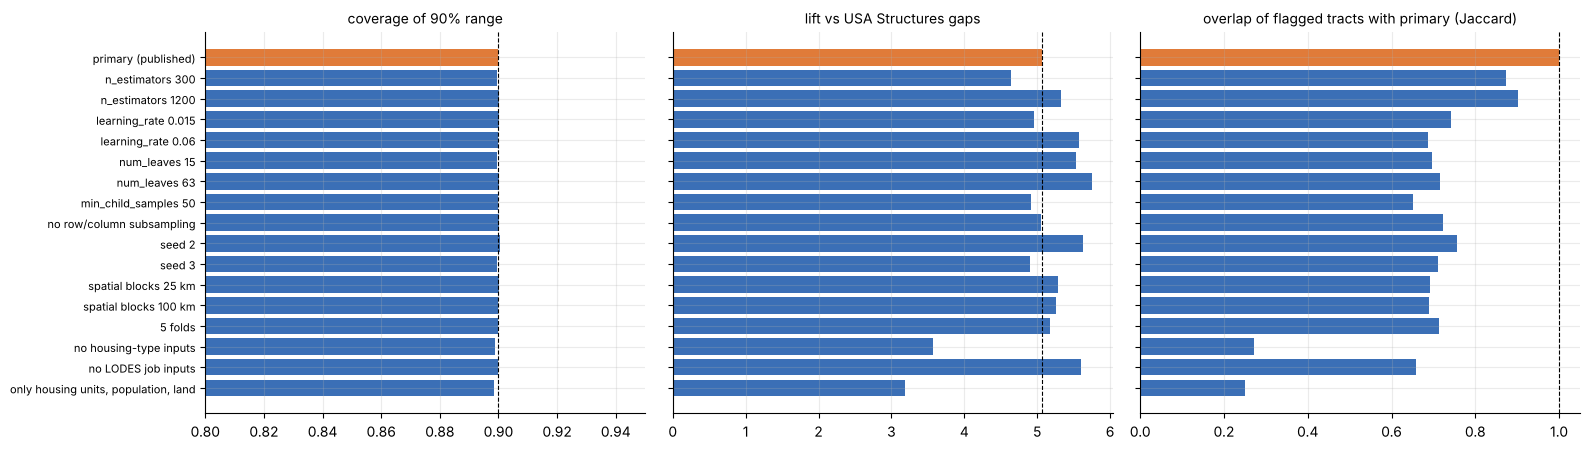

In [4]:
show = ["variant", "setting", "coverage", "cov_region_min", "cov_region_max", "n_flag", "r2_log", "mae_log", "width_log", "precision", "recall", "lift", "pr_auc", "flag_overlap_jaccard", "deficit_spearman_vs_primary"]
fmt = {c: "{:.3f}" for c in show[2:]} | {"n_flag": "{:,.0f}"}
display(g[show].style.format(fmt).background_gradient(subset=["flag_overlap_jaccard"], cmap="RdYlGn", vmin=0, vmax=1))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
yy = np.arange(len(g))[::-1]
for a, c, ref, lab in [(ax[0], "coverage", .90, "coverage of 90% range"), (ax[1], "lift", g.lift[0], "lift vs USA Structures gaps"), (ax[2], "flag_overlap_jaccard", 1, "overlap of flagged tracts with primary (Jaccard)")]:
    a.barh(yy, g[c], color=["#3b6fb6" if s != "-" else "#e07b39" for s in g.setting]); a.axvline(ref, color="k", ls="--", lw=.8); a.set_title(lab, fontsize=10)
ax[0].set_yticks(yy); ax[0].set_yticklabels(g.variant, fontsize=8); ax[0].set_xlim(.8, .95)
save("01_settings_sensitivity")

**Takeaway.** Coverage stays at 90.0% in every variant, because conformal calibration enforces it whatever the model. Fit and skill barely move with the LightGBM settings, the block size or the number of folds (R² 0.922-0.928, lift 4.6-5.7). What matters is the inputs: without the ACS housing-type columns R² falls from 0.926 to 0.845, the range widens by 43%, lift drops from 5.1 to 3.6 and three quarters of the flagged tracts change; with only housing units, population and land it is worse again (R² 0.778, lift 3.2). The LODES job inputs matter little for buildings (they were added for places).

## 4. How much changes from randomness alone?

In [5]:
seeds = g[g.setting.isin(["-", "randomness"])]
floor = g.loc[g.setting == "randomness", "flag_overlap_jaccard"].mean()
others = g[~g.setting.isin(["-", "randomness"])].assign(beyond_seed_noise=lambda x: x.flag_overlap_jaccard < floor - 0.05)
print(f"flag overlap between seeds (same settings): {floor:.2f}")
display(others[["variant", "setting", "flag_overlap_jaccard", "lift", "coverage", "beyond_seed_noise"]].style.format({"flag_overlap_jaccard": "{:.2f}", "lift": "{:.2f}", "coverage": "{:.3f}"}))

flag overlap between seeds (same settings): 0.73


,variant,setting,flag_overlap_jaccard,lift,coverage,beyond_seed_noise
1,n_estimators 300,LightGBM,0.87,4.64,0.900,False
2,n_estimators 1200,LightGBM,0.90,5.33,0.900,False
3,learning_rate 0.015,LightGBM,0.74,4.95,0.900,False
4,learning_rate 0.06,LightGBM,0.69,5.58,0.900,False
5,num_leaves 15,LightGBM,0.70,5.54,0.900,False
6,num_leaves 63,LightGBM,0.72,5.75,0.900,False
7,min_child_samples 50,LightGBM,0.65,4.92,0.900,True
8,no row/column subsampling,LightGBM,0.72,5.05,0.900,False
11,spatial blocks 25 km,validation,0.69,5.29,0.900,False
12,spatial blocks 100 km,validation,0.69,5.26,0.900,False


**Takeaway.** Changing nothing but the random seed already changes about a quarter of the flagged tracts (overlap 0.73). Every hyperparameter, block-size and fold-count variant falls within about that noise (overlap 0.65-0.90); only removing inputs moves far beyond it (0.25-0.27). So the untuned LightGBM settings are not a weakness, but individual tract flags are noisy: the paper should treat a flag as a probabilistic screen, and aggregate results (coverage, lift, group rates) are the robust quantities. Averaging flags over several seeds would make tract-level lists more stable.

## Summary

The model is reproducible, its calibration does not depend on its settings, and its skill depends on the inputs (the ACS housing-type columns above all), not on the LightGBM tuning. The main caveat is that a quarter of the flagged tracts change with the random seed alone, so tract-level flags should be read as a screen rather than a verdict.